<div dir="rtl">

# פרויקט זיהוי זיופים קוליים · שלב 1
## סקירת נתונים ו-Baseline (MFCC + רגרסיה לוגיסטית)

המחברת עושה שלושה דברים:
1. **סקירת נתונים** – התפלגות לפי מאגר, תווית, מערכת ודובר; מאפייני אות (שקט, עוצמה, רוחב פס); ספקטרוגרמות.
2. **Baseline** – MFCC + רגרסיה לוגיסטית, הערכה בפיצול **לפי דובר**, מדד EER.
3. **בדיקות קיצורי דרך והכללה** – מה ה-EER כשמשתמשים רק במאגר / רק בשקט, ומה קורה בין מאגרים.

**לפני ההרצה:** עדכנו את `DATA_DIR` ואת שמות העמודות בתא ההגדרות.

</div>

In [1]:
# ===== הגדרות – לעדכן לפי המבנה האמיתי של הנתונים =====
from pathlib import Path

DATA_DIR = Path("data")            # התיקייה שבה נמצאים train.csv וקובצי ה-WAV
CSV_PATH = DATA_DIR / "train.csv"
AUDIO_DIR = DATA_DIR               # אם הקבצים בתת-תיקייה, למשל DATA_DIR / "wav"

# שמות העמודות ב-train.csv (None = ניחוש אוטומטי לפי שמות נפוצים)
COLS = {
    "file":    None,   # שם קובץ / id
    "label":   None,   # bonafide/spoof, real/fake או 0/1
    "source":  None,   # מאגר: ASVspoof5 / CodecFake / AILABS-M
    "speaker": None,   # מזהה דובר
    "system":  None,   # מערכת זיוף (ריק לאמיתי)
}
SR = 16000
N_FOLDS = 5
SEED = 42
CACHE = Path("features_cache.npz")

In [2]:
import json, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, librosa.display
import soundfile as sf
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_curve, accuracy_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
rng = np.random.default_rng(SEED)

<div dir="rtl">

## 1. טעינת התוויות

</div>

In [3]:
df = pd.read_csv(CSV_PATH)
print("columns:", list(df.columns))

CANDIDATES = {
    "file":    ["file", "filename", "file_name", "path", "id", "utt", "utt_id", "wav"],
    "label":   ["label", "target", "is_fake", "class", "key"],
    "source":  ["source", "dataset", "corpus", "database", "db", "origin"],
    "speaker": ["speaker", "speaker_id", "spk", "spk_id"],
    "system":  ["system", "attack", "attack_id", "spoof_system", "codec", "method", "generator"],
}
lower = {c.lower(): c for c in df.columns}
for k, v in COLS.items():
    if v is None:
        COLS[k] = next((lower[c] for c in CANDIDATES[k] if c in lower), None)
print("column mapping:", COLS)
missing = [k for k in ("file", "label", "source", "speaker") if COLS[k] is None]
assert not missing, f"Set COLS manually for: {missing}"

d = pd.DataFrame({
    "file":    df[COLS["file"]].astype(str),
    "source":  df[COLS["source"]].astype(str),
    "speaker": df[COLS["source"]].astype(str) + "/" + df[COLS["speaker"]].astype(str),
    "system":  df[COLS["system"]].fillna("-").astype(str) if COLS["system"] else "-",
})
raw = df[COLS["label"]]
if raw.dtype.kind in "biuf":
    d["y"] = raw.astype(int).values
else:
    s = raw.astype(str).str.lower().str.strip()
    fake_words = {"spoof", "fake", "deepfake", "synthetic", "1", "true"}
    d["y"] = s.isin(fake_words).astype(int).values
print("label values:", raw.unique()[:10], "-> fake = 1")

def resolve(f):
    p = AUDIO_DIR / f
    if p.suffix == "":
        p = p.with_suffix(".wav")
    return p
d["path"] = d["file"].map(resolve)
print("files found:", d["path"].map(Path.exists).sum(), "/", len(d))
d.head()

columns: ['id', 'file', 'label', 'source', 'corpus', 'speaker', 'system', 'orig_file', 'orig_sr', 'orig_dur']
column mapping: {'file': 'file', 'label': 'label', 'source': 'source', 'speaker': 'speaker', 'system': 'system'}
label values: ['spoof' 'bonafide'] -> fake = 1
files found: 1484 / 1484


,file,source,speaker,system,y,path
0,wav/ASVspoof5/ASVspoof5_0000.wav,ASVspoof5,ASVspoof5/ASVspoof5:D_0062,A11,1,data/wav/ASVspoof5/ASVspoof5_0000.wav
1,wav/ASVspoof5/ASVspoof5_0001.wav,ASVspoof5,ASVspoof5/ASVspoof5:D_0755,A16,1,data/wav/ASVspoof5/ASVspoof5_0001.wav
2,wav/ASVspoof5/ASVspoof5_0002.wav,ASVspoof5,ASVspoof5/ASVspoof5:D_0106,A15,1,data/wav/ASVspoof5/ASVspoof5_0002.wav
3,wav/ASVspoof5/ASVspoof5_0003.wav,ASVspoof5,ASVspoof5/ASVspoof5:D_5368,A12,1,data/wav/ASVspoof5/ASVspoof5_0003.wav
4,wav/ASVspoof5/ASVspoof5_0004.wav,ASVspoof5,ASVspoof5/ASVspoof5:D_3166,A15,1,data/wav/ASVspoof5/ASVspoof5_0004.wav


<div dir="rtl">

## 2. התפלגות: מאגר, תווית, מערכת, דובר

</div>

In [4]:
print("=== source x label (1 = fake) ===")
display(pd.crosstab(d["source"], d["y"], margins=True))

print("=== fakes per system ===")
display(d[d.y == 1].groupby(["source", "system"]).size().rename("n").to_frame())

spk = d.groupby("source").agg(n_clips=("file", "size"), n_speakers=("speaker", "nunique"))
spk["clips_per_speaker"] = (spk.n_clips / spk.n_speakers).round(1)
print("=== speakers per source ===")
display(spk)

both = d.groupby("speaker")["y"].nunique()
print(f"speakers that appear in BOTH real and fake: {(both == 2).sum()} / {len(both)}")

=== source x label (1 = fake) ===


y,0,1,All
source,,,
ASVspoof5,300,300,600
CodecFake,300,300,600
LibriSpeech,284,0,284
All,884,600,1484


=== fakes per system ===


n
source    system                                            
ASVspoof5 A09                                             37
          A10                                             37
          A11                                             38
          A12                                             38
          A13                                             38
          A14                                             37
          A15                                             37
          A16                                             38
CodecFake academicodec_hifi_16k_320d                      30
          academicodec_hifi_16k_320d_large_uni            30
          descript-audio-codec-16khz                      30
          descript-audio-codec-24khz                      30
          descript-audio-codec-44khz                      30
          encodec_24khz                                   30
          funcodec-funcodec_en_libritts-16k-gr1nq32ds320  30
          funcodec-funcodec_en_libritts-16k-gr8nq32ds320  30
          funcodec-funcodec_en_libritts-16k-nq32ds640     30
          funcodec-funcodec_zh_en_general_16k_nq32ds640   30

=== speakers per source ===


,n_clips,n_speakers,clips_per_speaker
source,,,
ASVspoof5,600,361,1.7
CodecFake,600,99,6.1
LibriSpeech,284,40,7.1


speakers that appear in BOTH real and fake: 169 / 500


<div dir="rtl">

**מה לחפש:** מאגר עם תווית אחת בלבד (AILABS-M), מערכות זיוף עם מעט מאוד קטעים, ודוברים שמופיעים בשתי המחלקות – אלה חייבים להיות באותו צד של הפיצול.

## 3. מאפייני אות לפי מאגר ותווית

</div>

In [5]:
def signal_stats(path):
    y, sr = librosa.load(path, sr=SR, mono=True)
    _, (a, b) = librosa.effects.trim(y, top_db=35)
    S = np.abs(librosa.stft(y, n_fft=1024)) ** 2
    spec = S.mean(axis=1)
    cum = np.cumsum(spec) / spec.sum()
    freqs = librosa.fft_frequencies(sr=sr, n_fft=1024)
    return dict(
        dur=len(y) / sr,
        rms_db=20 * np.log10(np.sqrt(np.mean(y ** 2)) + 1e-9),
        lead_sil=a / sr,
        trail_sil=(len(y) - b) / sr,
        zero_frac=float(np.mean(np.abs(y) < 1e-5)),
        bw99=float(freqs[np.searchsorted(cum, 0.99)]),
    )

stats = pd.DataFrame([signal_stats(p) for p in d["path"]])
d = pd.concat([d.drop(columns=stats.columns, errors="ignore"), stats], axis=1)
display(d.groupby(["source", "y"])[stats.columns].median().round(3))

dur     rms_db  lead_sil  trail_sil  zero_frac      bw99
source      y                                                          
ASVspoof5   0  4.0 -19.427999       0.0      0.000      0.005  4601.562
            1  4.0 -18.497999       0.0      0.000      0.006  4257.812
CodecFake   0  4.0 -25.934000       0.0      0.320      0.084  3687.500
            1  4.0 -25.528000       0.0      0.192      0.040  3453.125
LibriSpeech 0  4.0 -24.245001       0.0      0.000      0.002  4109.375

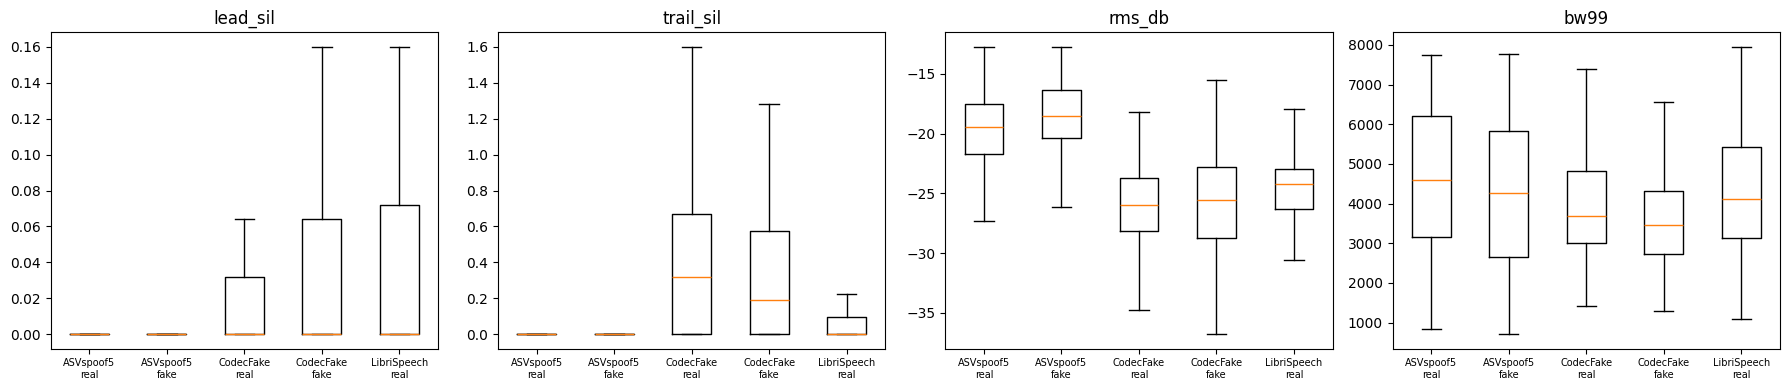

In [6]:
cols = ["lead_sil", "trail_sil", "rms_db", "bw99"]
fig, axes = plt.subplots(1, len(cols), figsize=(18, 4))
groups = [(s, y) for s in sorted(d.source.unique()) for y in (0, 1) if ((d.source == s) & (d.y == y)).any()]
for ax, c in zip(axes, cols):
    ax.boxplot([d.loc[(d.source == s) & (d.y == y), c] for s, y in groups], showfliers=False)
    ax.set_xticks(range(1, len(groups) + 1), [f"{s}\n{'fake' if y else 'real'}" for s, y in groups])
    ax.set_title(c); ax.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

<div dir="rtl">

**מה לחפש:** אם השקט, העוצמה או רוחב הפס נבדלים בבירור בין אמיתי למזויף **בתוך** מאגר, מודל יכול ללמוד אותם במקום סימני זיוף. אם הם נבדלים בעיקר **בין מאגרים**, הם מאפשרים לזהות את המאגר.

## 4. ספקטרום ממוצע וספקטרוגרמות לדוגמה

</div>

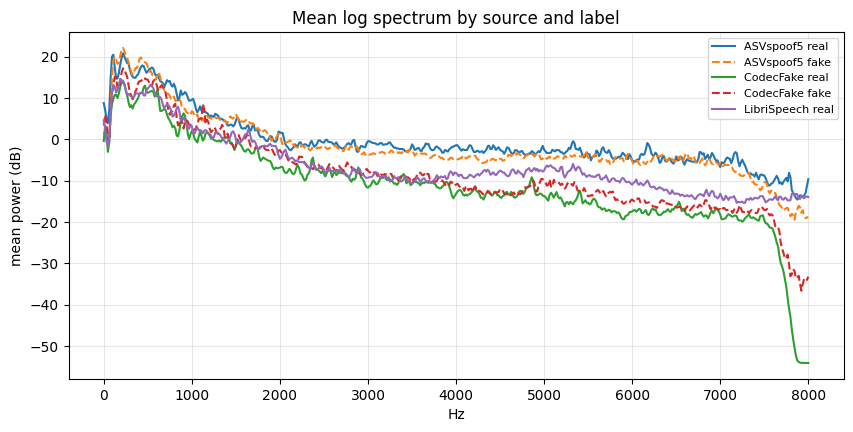

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
freqs = librosa.fft_frequencies(sr=SR, n_fft=1024)
for (s, y) in groups:
    paths = d.loc[(d.source == s) & (d.y == y), "path"].sample(min(40, ((d.source == s) & (d.y == y)).sum()), random_state=SEED)
    specs = [np.mean(np.abs(librosa.stft(librosa.load(p, sr=SR)[0], n_fft=1024)) ** 2, axis=1) for p in paths]
    ax.plot(freqs, 10 * np.log10(np.mean(specs, axis=0) + 1e-12), label=f"{s} {'fake' if y else 'real'}", ls="--" if y else "-")
ax.set_xlabel("Hz"); ax.set_ylabel("mean power (dB)"); ax.legend(fontsize=8); ax.grid(alpha=.3)
ax.set_title("Mean log spectrum by source and label"); plt.show()

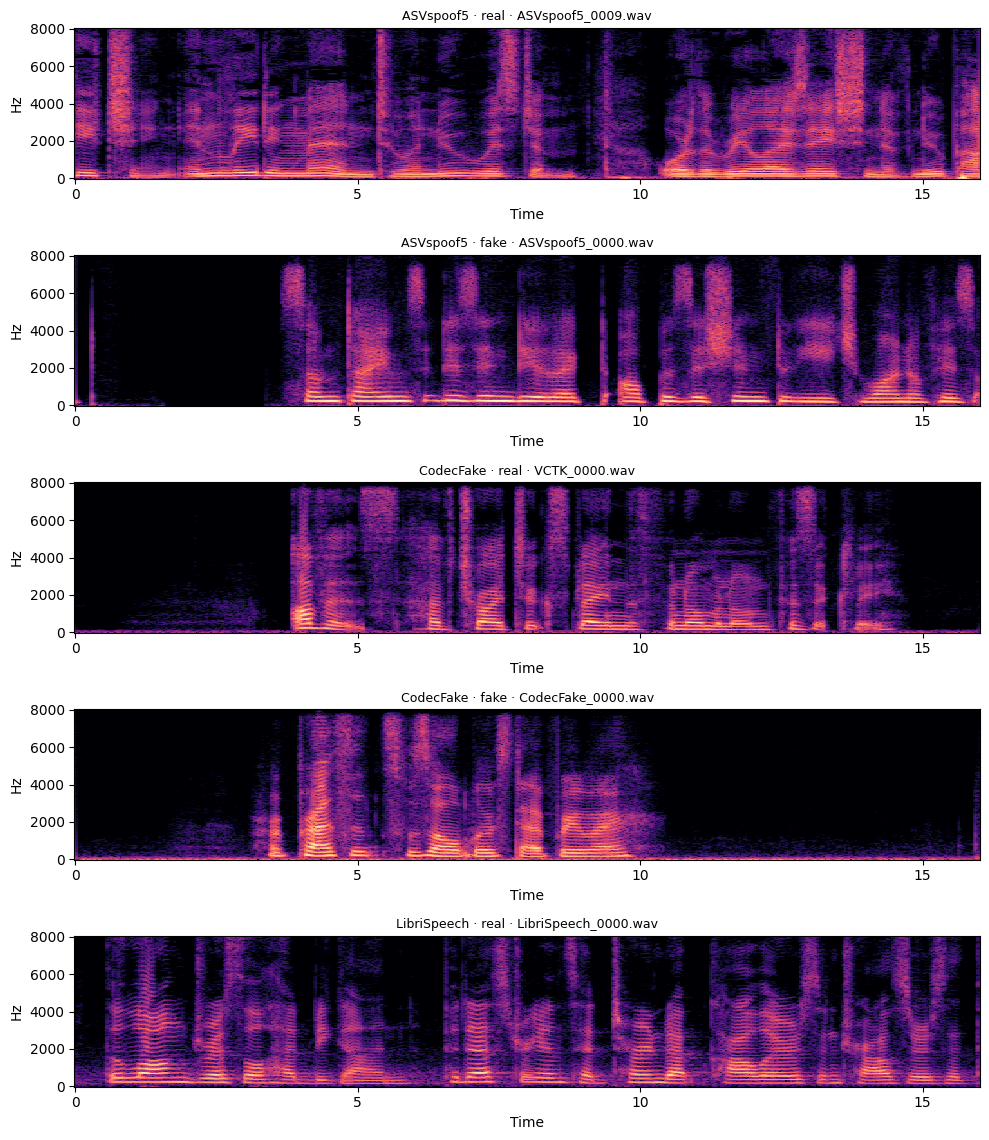

In [8]:
fig, axes = plt.subplots(len(groups), 1, figsize=(10, 2.3 * len(groups)))
for ax, (s, y) in zip(np.atleast_1d(axes), groups):
    p = d.loc[(d.source == s) & (d.y == y), "path"].iloc[0]
    sig, _ = librosa.load(p, sr=SR)
    S = librosa.amplitude_to_db(np.abs(librosa.stft(sig, n_fft=512)), ref=np.max)
    librosa.display.specshow(S, sr=SR, x_axis="time", y_axis="hz", ax=ax)
    ax.set_title(f"{s} · {'fake' if y else 'real'} · {Path(p).name}", fontsize=9)
plt.tight_layout(); plt.show()
# להאזנה במחברת:  from IPython.display import Audio; Audio(str(path))

<div dir="rtl">

## 5. פיצ'רים ל-Baseline: MFCC

20 מקדמי MFCC + דלתא + דלתא-דלתא לכל פריים, ואז ממוצע וסטיית תקן על פני הזמן ⇒ וקטור של 120 ערכים לכל קטע.

</div>

In [9]:
def mfcc_vec(path, n_mfcc=20):
    y, _ = librosa.load(path, sr=SR)
    m = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=n_mfcc, n_fft=512, hop_length=160, n_mels=40)
    f = np.vstack([m, librosa.feature.delta(m), librosa.feature.delta(m, order=2)])
    return np.concatenate([f.mean(axis=1), f.std(axis=1)])

if CACHE.exists() and len(np.load(CACHE)["X"]) == len(d):
    X = np.load(CACHE)["X"]
else:
    X = np.stack([mfcc_vec(p) for p in d["path"]])
    np.savez(CACHE, X=X)
y = d["y"].values
print("X:", X.shape)

X: (1484, 120)


<div dir="rtl">

## 6. מדד EER ופרוטוקול הערכה

EER הוא הסף שבו שיעור הזיופים שהוחמצו שווה לשיעור האזעקות השגויות. הפיצול הוא `StratifiedGroupKFold` לפי **דובר**, כך שאף דובר לא מופיע גם באימון וגם בבדיקה. כל קטע מקבל ציון מהקפל שבו הוא היה בבדיקה (out-of-fold).

</div>

In [10]:
def eer(y_true, score):
    y_true = np.asarray(y_true); score = np.asarray(score)
    if len(np.unique(y_true)) < 2:
        return np.nan
    fpr, tpr, _ = roc_curve(y_true, score)
    fnr = 1 - tpr
    i = np.nanargmin(np.abs(fnr - fpr))
    return float((fpr[i] + fnr[i]) / 2)

def baseline():
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000))

def oof_scores(X, y, groups=None, model_fn=baseline):
    if groups is None:
        cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED); split = cv.split(X, y)
    else:
        cv = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED); split = cv.split(X, y, groups)
    s = np.zeros(len(y))
    for tr, te in split:
        m = model_fn().fit(X[tr], y[tr])
        s[te] = m.predict_proba(X[te])[:, 1]
    return s

def report(score, name):
    rows = {"model": name, "EER all": eer(y, score)}
    for src in sorted(d.source.unique()):
        m = (d.source == src).values
        rows[f"EER {src}"] = eer(y[m], score[m])
    m = (d.source.isin([s for s in d.source.unique() if d.loc[d.source == s, 'y'].nunique() == 2])).values
    rows["EER excl. real-only sources"] = eer(y[m], score[m])
    return rows

score_spk = oof_scores(X, y, groups=d["speaker"].astype(str).to_numpy(dtype=object))
results = [report(score_spk, "MFCC+LR · speaker split")]
pd.DataFrame(results).round(3)

,model,EER all,EER ASVspoof5,EER CodecFake,EER LibriSpeech,EER excl. real-only sources
0,MFCC+LR · speaker split,0.293,0.213,0.413,NaN,0.315


<div dir="rtl">

### EER לפי מערכת זיוף
לכל מערכת: הזיופים שלה מול **כל** הקטעים האמיתיים של אותו מאגר.

</div>

In [11]:
rows = []
for (src, sysname), g in d[d.y == 1].groupby(["source", "system"]):
    m = ((d.source == src) & ((d.y == 0) | (d.system == sysname))).values
    rows.append({"source": src, "system": sysname, "n_fake": len(g), "EER": eer(y[m], score_spk[m])})
per_sys = pd.DataFrame(rows).sort_values("EER", ascending=False)
per_sys.round(3)

,source,system,n_fake,EER
15,CodecFake,funcodec-funcodec_en_libritts-16k-gr8nq32ds320,30,0.693
17,CodecFake,funcodec-funcodec_zh_en_general_16k_nq32ds640,30,0.607
16,CodecFake,funcodec-funcodec_en_libritts-16k-nq32ds640,30,0.492
11,CodecFake,descript-audio-codec-24khz,30,0.468
10,CodecFake,descript-audio-codec-16khz,30,0.395
14,CodecFake,funcodec-funcodec_en_libritts-16k-gr1nq32ds320,30,0.377
3,ASVspoof5,A12,38,0.369
12,CodecFake,descript-audio-codec-44khz,30,0.333
8,CodecFake,academicodec_hifi_16k_320d,30,0.330
6,ASVspoof5,A15,37,0.294


<div dir="rtl">

## 7. בדיקות קיצורי דרך ודליפה

1. **פיצול אקראי מול פיצול לפי דובר** – אם הפיצול האקראי נותן EER נמוך משמעותית, ההערכה האקראית אופטימית מדי.
2. **ציון לפי מאגר בלבד** – הציון הוא שיעור הזיופים במאגר (מחושב על קפלי האימון). זה ה-EER ש"קיצור הדרך" נותן בחינם.
3. **מסווג מאגרים** – האם MFCC מזהה את המאגר? דיוק קרוב ל-100% אומר שהמידע זמין למודל.
4. **שקט בלבד** – מודל שרואה רק את משך השקט בתחילת ובסוף הקטע.

</div>

In [12]:
groups_spk = d["speaker"].astype(str).to_numpy(dtype=object)

# 1. random split
score_rand = oof_scores(X, y, groups=None)
results.append(report(score_rand, "MFCC+LR · random split (leaky?)"))

# 2. source-only score (base rate per source, learned on training folds)
src_codes = pd.get_dummies(d["source"]).values.astype(float)
score_src = oof_scores(src_codes, y, groups=groups_spk,
                       model_fn=lambda: LogisticRegression(max_iter=1000))
results.append(report(score_src, "source only (shortcut)"))

# 4. silence only
Xsil = d[["lead_sil", "trail_sil"]].values
score_sil = oof_scores(Xsil, y, groups=groups_spk)
results.append(report(score_sil, "silence only (shortcut)"))

display(pd.DataFrame(results).round(3))

# 3. source classifier
src_pred = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
                             X, d["source"].astype(str).to_numpy(dtype=object),
                             cv=StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED),
                             groups=groups_spk)
print(f"source classifier accuracy from MFCC: {accuracy_score(d.source, src_pred):.1%} "
      f"(chance ≈ {d.source.value_counts(normalize=True).max():.1%})")

,model,EER all,EER ASVspoof5,EER CodecFake,EER LibriSpeech,EER excl. real-only sources
0,MFCC+LR · speaker split,0.293,0.213,0.413,NaN,0.315
1,MFCC+LR · random split (leaky?),0.297,0.208,0.427,NaN,0.328
2,source only (shortcut),0.413,0.513,0.505,NaN,0.509
3,silence only (shortcut),0.514,0.515,0.502,NaN,0.510


source classifier accuracy from MFCC: 85.0% (chance ≈ 40.4%)


<div dir="rtl">

## 8. הכללה בין מאגרים

מאמנים על מאגר אחד שיש בו זיופים ובודקים על השני – זה המבחן הקרוב ביותר ל"שיטת זיוף שלא נראתה".

</div>

In [13]:
two_class = [s for s in sorted(d.source.unique()) if d.loc[d.source == s, "y"].nunique() == 2]
cross = []
for tr_src in two_class:
    for te_src in two_class:
        tr = (d.source == tr_src).values; te = (d.source == te_src).values
        if tr_src == te_src:
            s = oof_scores(X[tr], y[tr], groups=groups_spk[tr]); val = eer(y[tr], s)
        else:
            m = baseline().fit(X[tr], y[tr]); val = eer(y[te], m.predict_proba(X[te])[:, 1])
        cross.append({"train": tr_src, "test": te_src, "EER": val})
cross = pd.DataFrame(cross).pivot(index="train", columns="test", values="EER")
cross.round(3)

test,ASVspoof5,CodecFake
train,,
ASVspoof5,0.183,0.493
CodecFake,0.457,0.408


<div dir="rtl">

**קריאה:** האלכסון הוא EER בתוך אותו מאגר (פיצול לפי דובר); מחוץ לאלכסון – הכללה. פער גדול בין האלכסון לשאר הוא בדיוק הפער בין סיכון אמפירי לסיכון אמיתי משיעור 1.

## 9. שמירת תוצאות וגרף DET/ROC

</div>

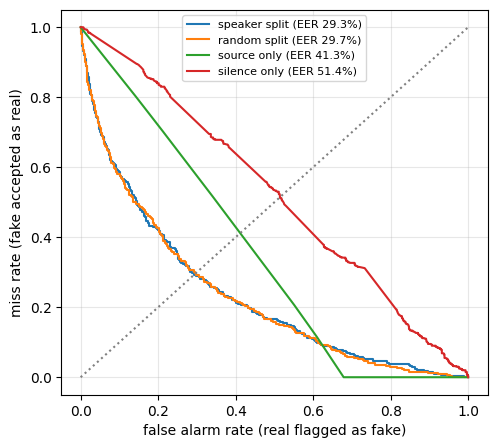

saved stage1_results.json


In [14]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, s in [("speaker split", score_spk), ("random split", score_rand),
                ("source only", score_src), ("silence only", score_sil)]:
    fpr, tpr, _ = roc_curve(y, s)
    ax.plot(fpr, 1 - tpr, label=f"{name} (EER {eer(y, s):.1%})")
ax.plot([0, 1], [0, 1], ":", color="gray")
ax.set_xlabel("false alarm rate (real flagged as fake)")
ax.set_ylabel("miss rate (fake accepted as real)")
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.show()

out = {
    "summary": pd.DataFrame(results).round(4).to_dict(orient="records"),
    "per_system": per_sys.round(4).to_dict(orient="records"),
    "cross_dataset": cross.round(4).to_dict(),
}
Path("stage1_results.json").write_text(json.dumps(out, indent=2, ensure_ascii=False))
print("saved stage1_results.json")

<div dir="rtl">

## 10. תבנית לקובץ ההגשה לתחרות

הפורמט: `id,score`, ציון גבוה = יותר סביר שמזויף. מאמנים פעם אחת על כל נתוני האימון – **בלי** לגעת בקטעי המבחן באימון.

</div>

In [15]:
def make_submission(test_dir, out_csv="submission.csv"):
    final = baseline().fit(X, y)
    files = sorted(Path(test_dir).glob("*.wav"))
    Xt = np.stack([mfcc_vec(p) for p in files])
    pd.DataFrame({"id": [p.stem for p in files],
                  "score": final.predict_proba(Xt)[:, 1]}).to_csv(out_csv, index=False)
    return out_csv
# make_submission("data/test")   # רק כשקטעי המבחן יפורסמו